# Batch simulation data analysis
---

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

### Import batch_results.csv

In [86]:
batch_results = pd.read_csv("../results/batch_results.csv")
batch_results.head()

,x,theta,success,settle_time
0,0.165166,-141.667429,True,5.43
1,0.294964,93.476014,True,5.21
2,0.036087,29.544828,True,5.31
3,-0.020232,168.199203,True,6.54
4,0.247814,-10.567317,True,6.32


<Axes: xlabel='theta'>

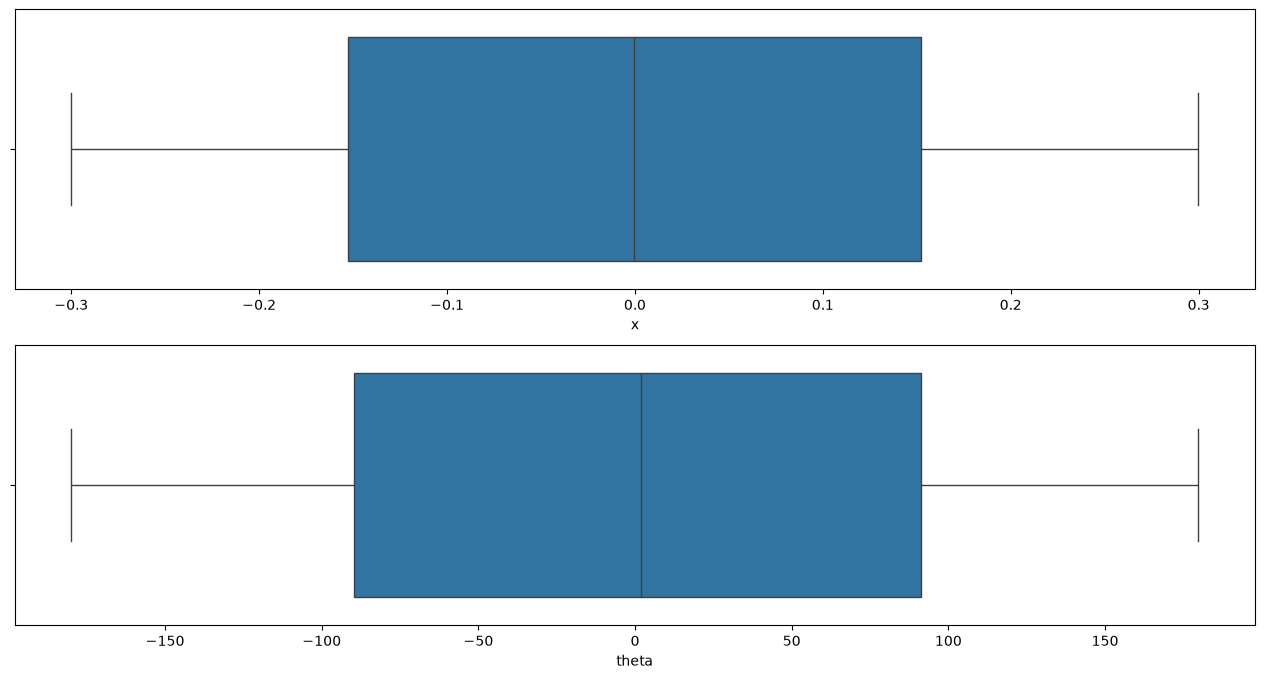

In [87]:
f, axes = plt.subplots(2, 1, figsize=(16, 8))
sb.boxplot(data=batch_results["x"], ax=axes[0], orient="h")
sb.boxplot(data=batch_results["theta"], ax=axes[1], orient="h")

### Successful runs

In [88]:
successful_runs = batch_results.loc[batch_results["success"]==True]
successful_runs.head()

,x,theta,success,settle_time
0,0.165166,-141.667429,True,5.43
1,0.294964,93.476014,True,5.21
2,0.036087,29.544828,True,5.31
3,-0.020232,168.199203,True,6.54
4,0.247814,-10.567317,True,6.32


(0.0, 10.0)

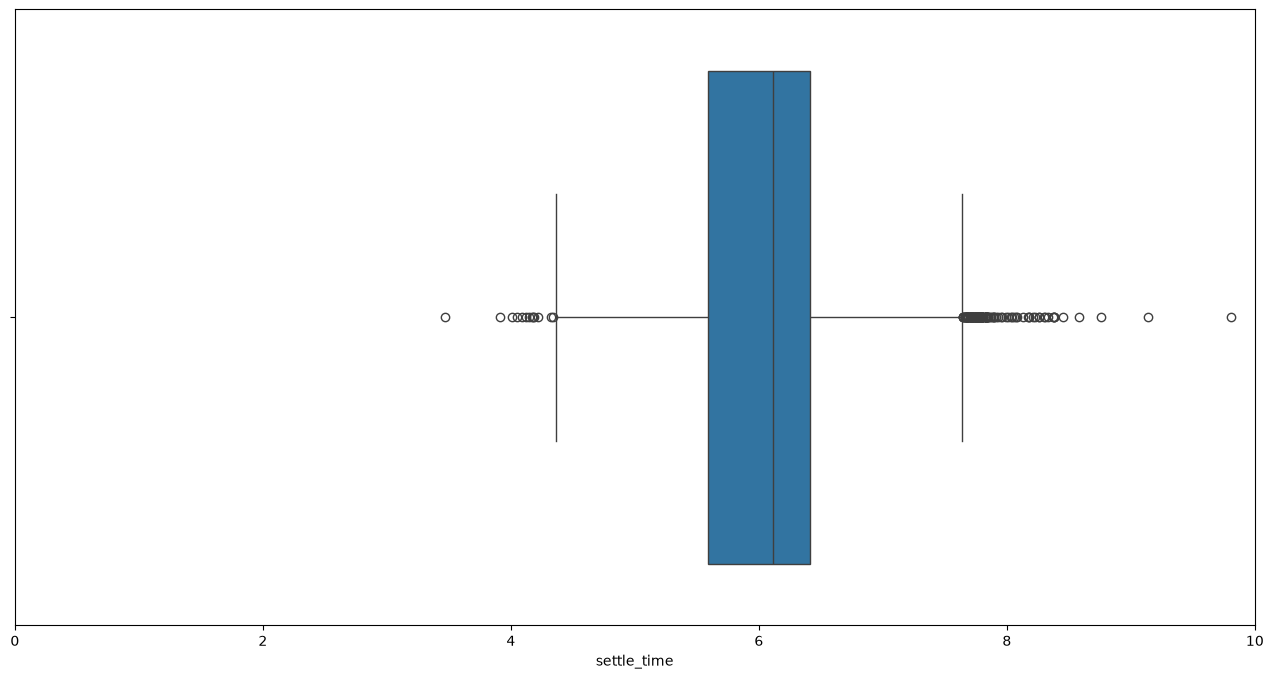

In [89]:
f = plt.figure(figsize=(16, 8))
sb.boxplot(successful_runs["settle_time"], orient="h")
plt.xlim(0, 10)

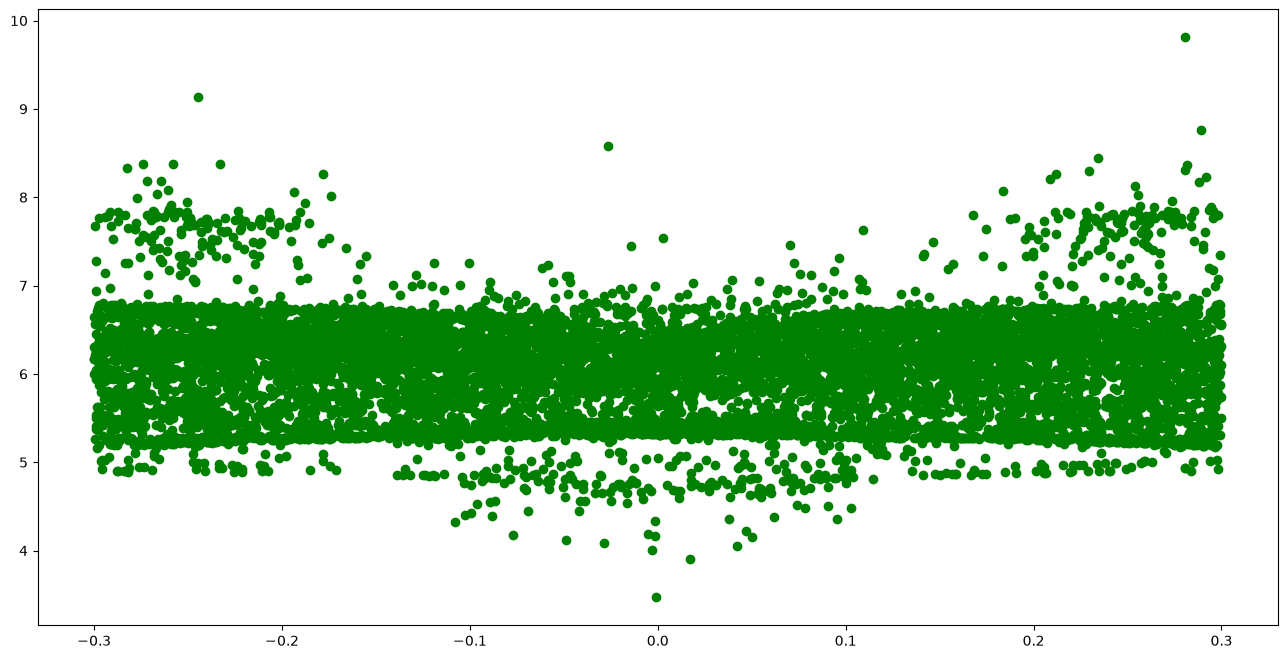

In [90]:
f = plt.figure(figsize=(16, 8))
plt.scatter(successful_runs["x"], successful_runs["settle_time"], color="green")

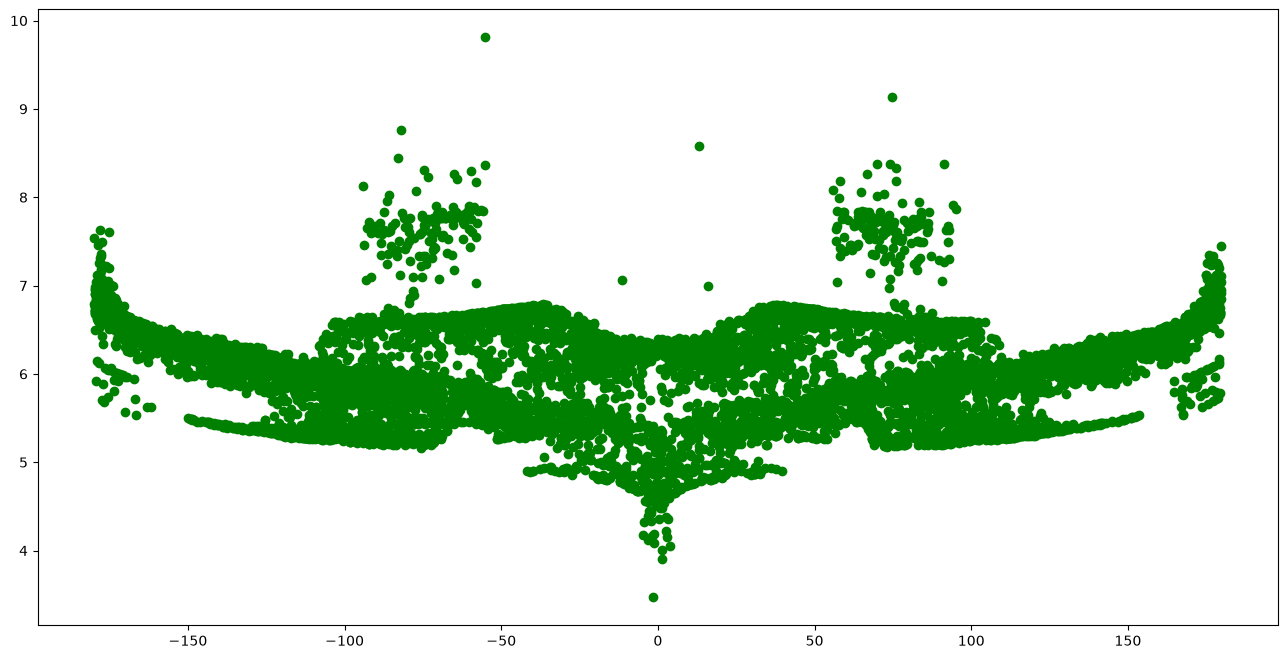

In [91]:
f = plt.figure(figsize=(16, 8))
plt.scatter(successful_runs["theta"], successful_runs["settle_time"], color="green")

### Failed runs

In [92]:
failed_runs = batch_results.loc[batch_results["success"]==False]
failed_runs.info()

<class 'pandas.DataFrame'>
Index: 31 entries, 224 to 9619
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   x            31 non-null     float64
 1   theta        31 non-null     float64
 2   success      31 non-null     bool   
 3   settle_time  31 non-null     float64
dtypes: bool(1), float64(3)
memory usage: 1023.0 bytes


## Analyse relationship between initial state conditions and success

<Axes: xlabel='theta', ylabel='success'>

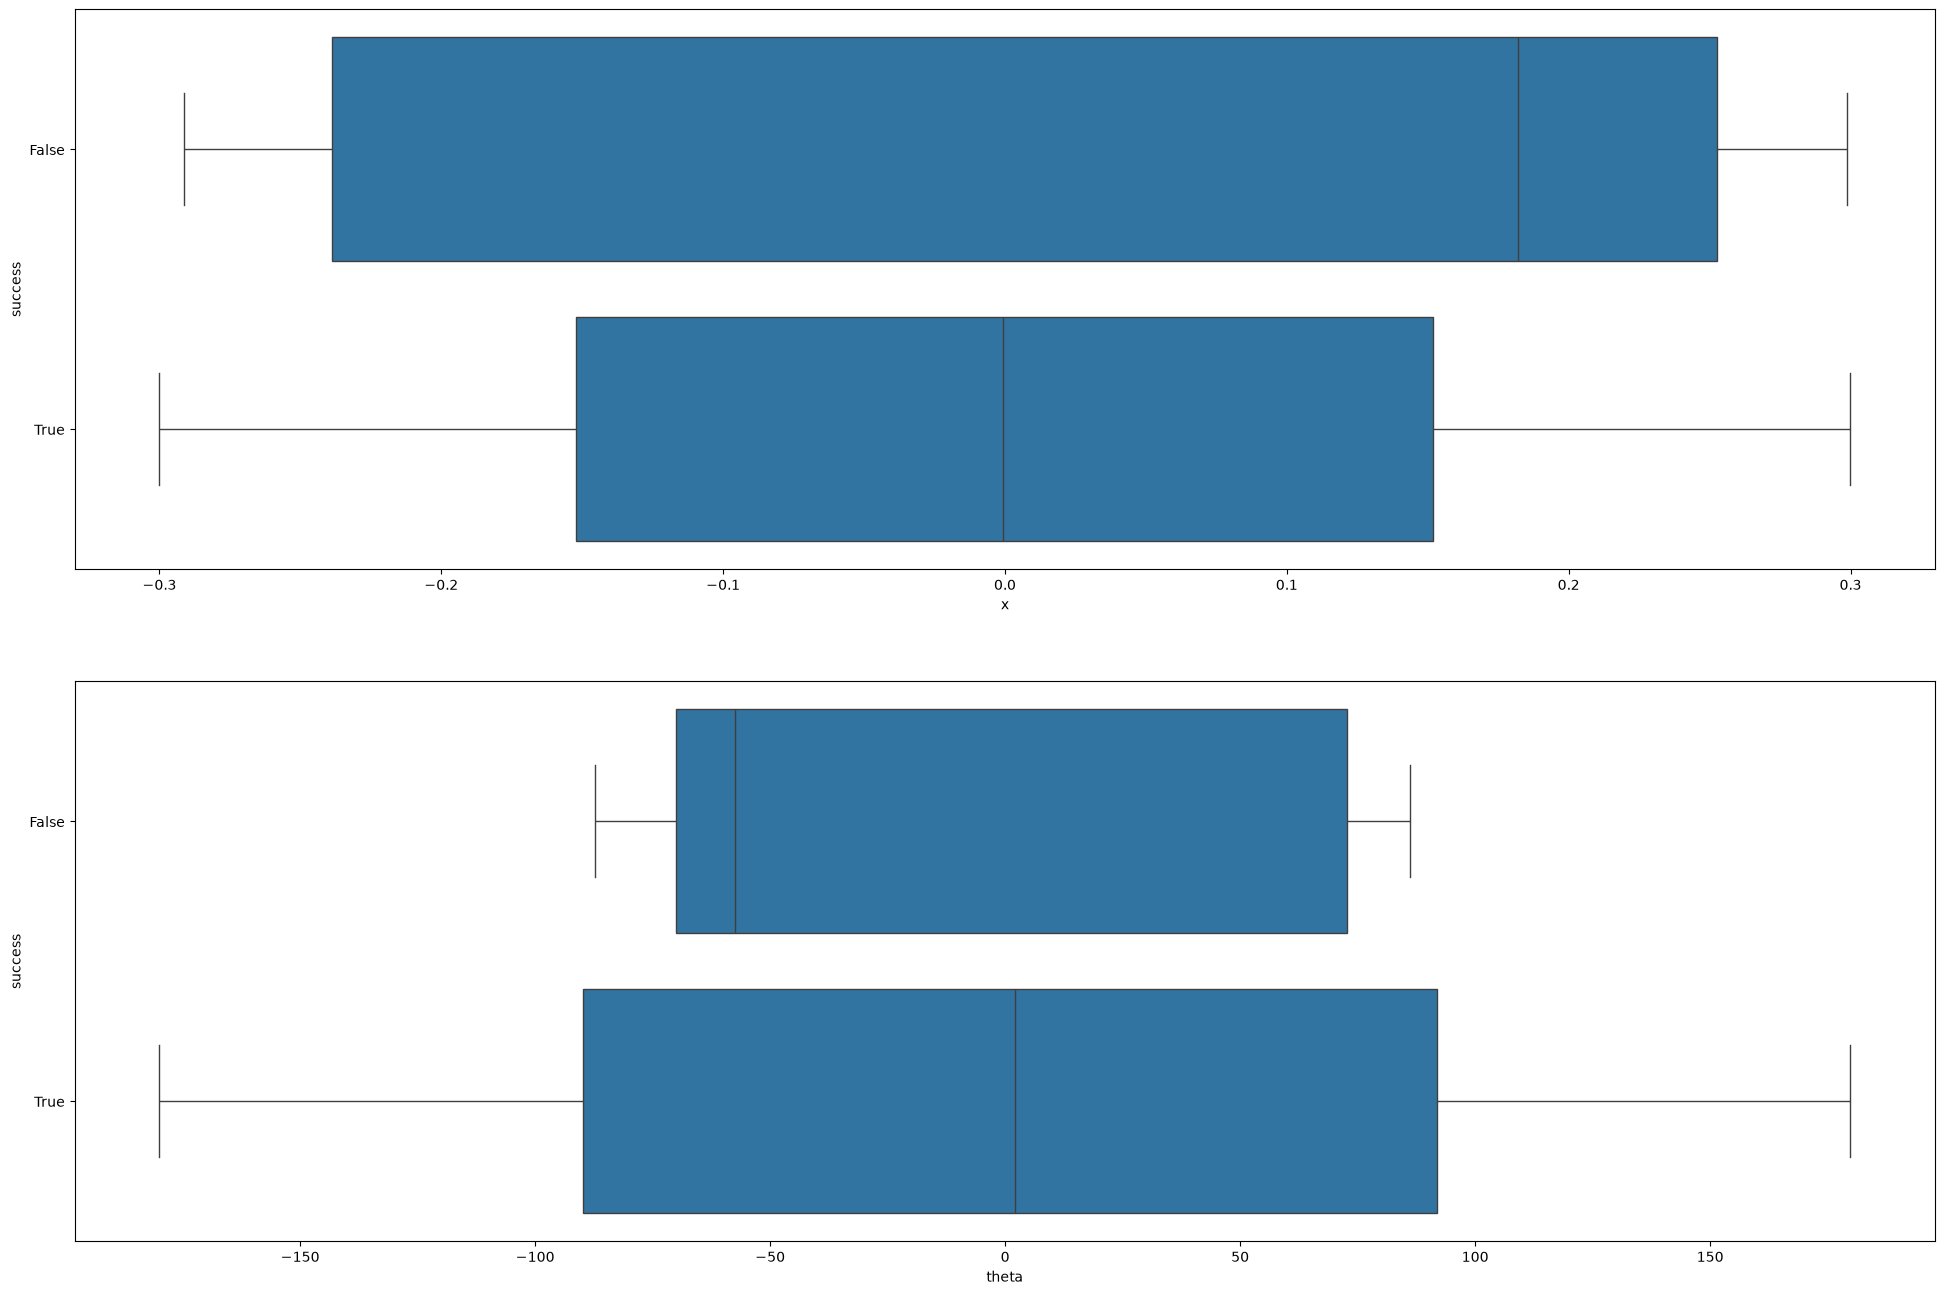

In [93]:
f, axes = plt.subplots(2, 1, figsize=(24, 16))
sb.boxplot(x = "x", y = "success", data = batch_results, orient = "h", ax=axes[0])
sb.boxplot(x = "theta", y = "success", data = batch_results, orient = "h", ax=axes[1])

### Import last_reset_states.csv

In [94]:
last_reset_states = pd.read_csv("../results/last_reset_states.csv")
last_reset_states.head()

,success,x,v,theta,omega,energy
0,True,-0.002791,0.019388,0.010592,-0.160738,-1.470976
1,True,0.005859,-0.024239,-0.019419,0.083678,-1.471101
2,True,0.009340,-0.024924,-0.006705,0.001583,-1.471467
3,True,-0.006274,0.002685,-0.007028,0.167759,-1.470989
4,True,-0.004744,0.024369,0.006937,-0.018905,-1.471457


In [95]:
# Data cleaning
last_reset_states_clean = last_reset_states[last_reset_states["energy"] < 0]
last_reset_states_clean

,success,x,v,theta,omega,energy
0,True,-0.002791,0.019388,0.010592,-0.160738,-1.470976
1,True,0.005859,-0.024239,-0.019419,0.083678,-1.471101
2,True,0.009340,-0.024924,-0.006705,0.001583,-1.471467
3,True,-0.006274,0.002685,-0.007028,0.167759,-1.470989
4,True,-0.004744,0.024369,0.006937,-0.018905,-1.471457
...,...,...,...,...,...,...
9995,True,0.006020,-0.023810,-0.012776,0.148693,-1.471003
9996,True,0.007731,-0.007926,0.006443,-0.172290,-1.470971
9997,True,0.007283,-0.024454,-0.005124,0.027714,-1.471466
9998,True,-0.007391,0.024848,0.005180,-0.028172,-1.471465


## Analyse relationship between state conditions before swingup and success

<Axes: xlabel='energy', ylabel='success'>

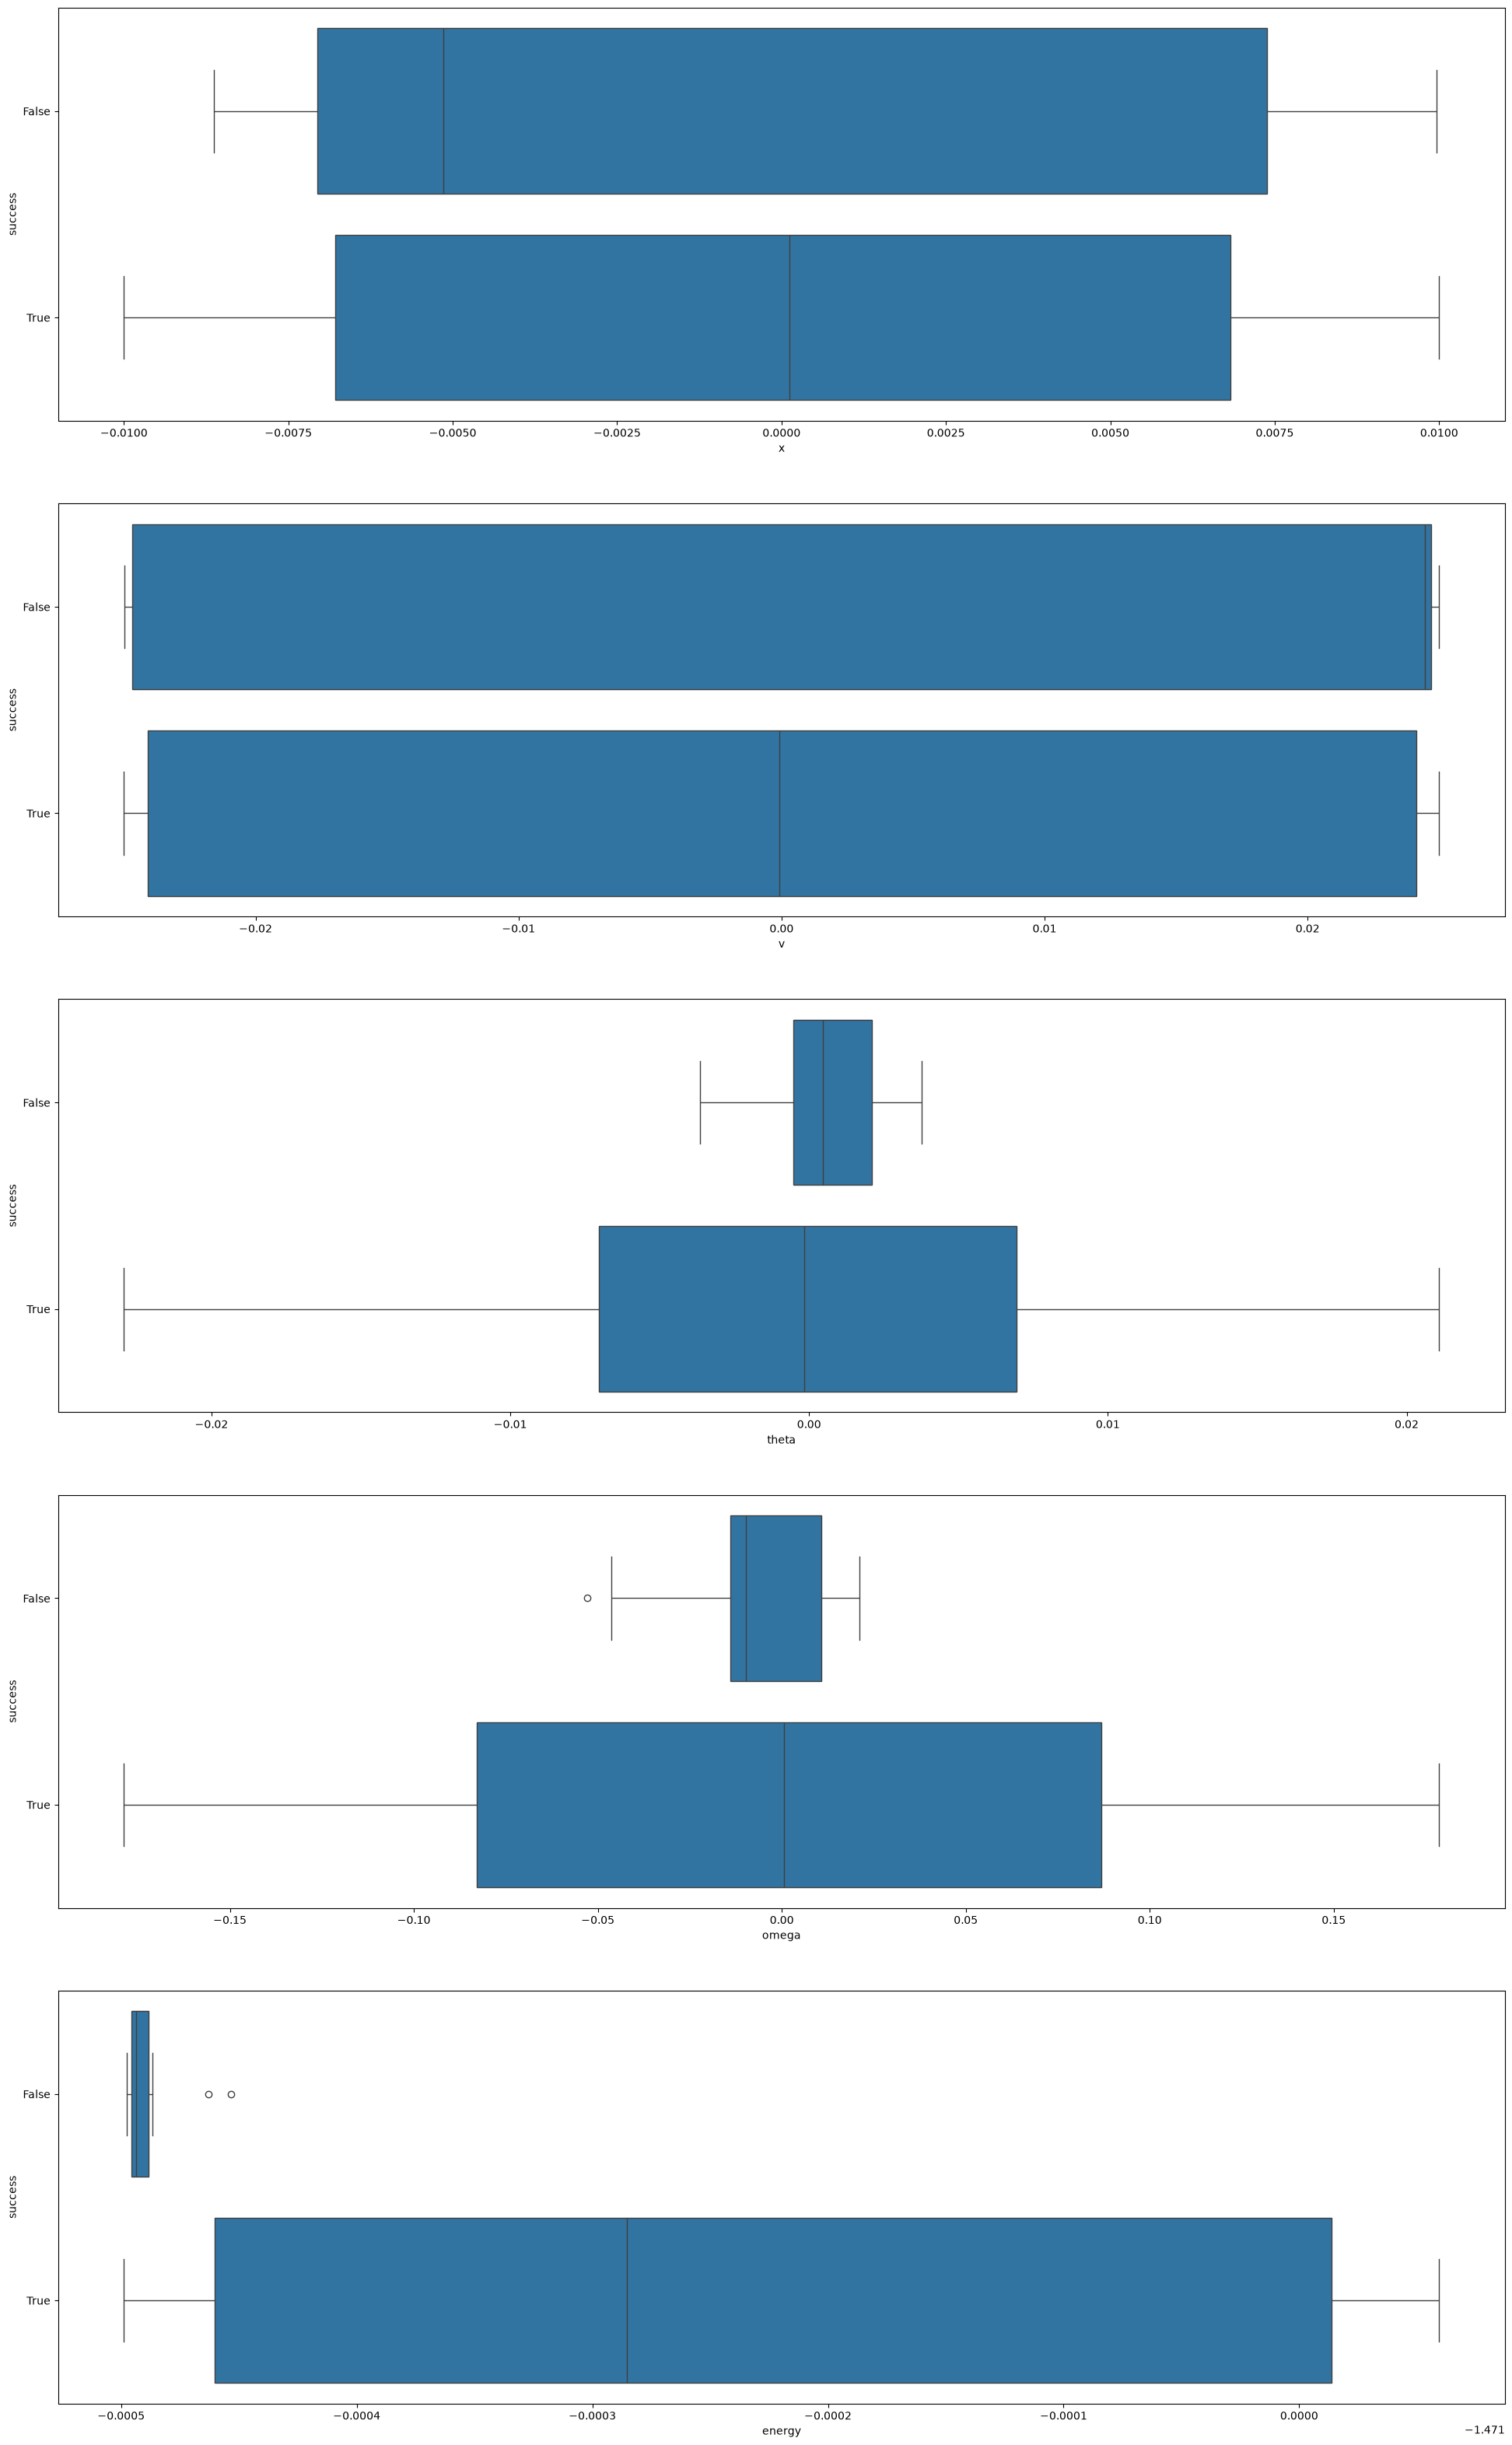

In [96]:
f, axes = plt.subplots(5, 1, figsize=(24, 40))
sb.boxplot(x = "x", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[0])
sb.boxplot(x = "v", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[1])
sb.boxplot(x = "theta", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[2])
sb.boxplot(x = "omega", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[3])
sb.boxplot(x = "energy", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[4])

Text(0, 0.5, 'Minimum energy before swingup')

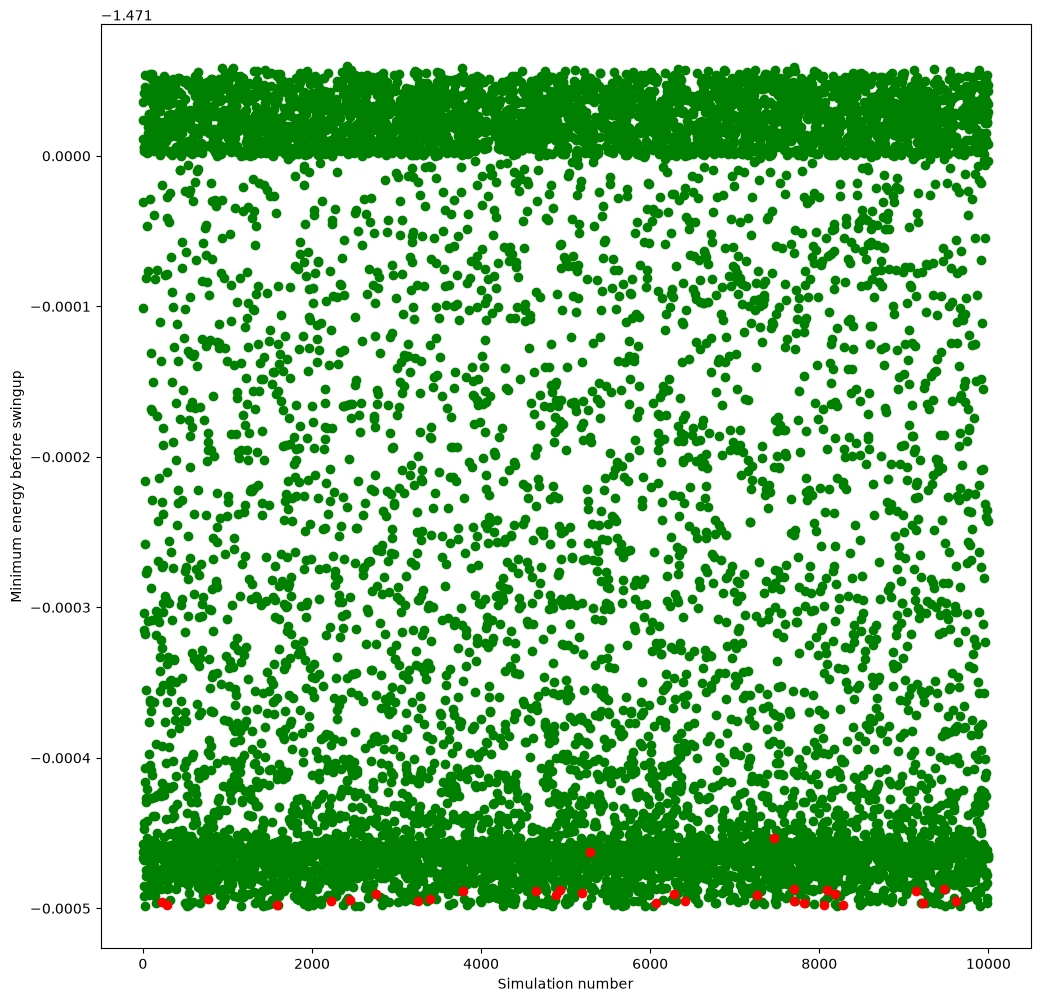

In [97]:
f = plt.figure(figsize=(12, 12))
plt.scatter(last_reset_states_clean[last_reset_states_clean["success"]==True].index, last_reset_states_clean[last_reset_states_clean["success"]==True]["energy"], color="green")
plt.scatter(last_reset_states_clean[last_reset_states_clean["success"]==False].index, last_reset_states_clean[last_reset_states_clean["success"]==False]["energy"], color="red")
plt.xlabel("Simulation number")
plt.ylabel("Minimum energy before swingup")